## Análisis de modelos

## Regresión lineal

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
import joblib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import mlflow


In [23]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


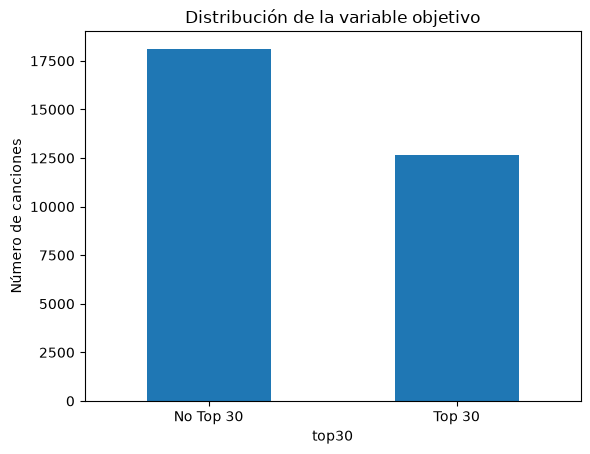

In [24]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [25]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


In [26]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(24923, 13)

Columnas con nulos:
spotify_track_duration_ms    2976
spotify_track_explicit       2976
danceability                 3025
key                          3025
loudness                     3025
mode                         3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
time_signature               3025
dtype: int64


## Aplicamos el análisis en X_train

In [27]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
loudness                     3025
key                          3025
mode                         3025
time_signature               3025
spotify_track_duration_ms    2976
spotify_track_explicit       2976
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6020063932779248), 'speechiness': np.float64(0.08950473102566445), 'instrumentalness': np.float64(0.032657926696501964), 'tempo': np.float64(121.06935149328706), 'loudness': -8.13, 'key': np.float64(0.0), 'mode'

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_5228\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [28]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 319
speechiness                  319
instrumentalness             319
tempo                        319
loudness                     319
key                          319
mode                         319
time_signature               319
spotify_track_duration_ms    315
spotify_track_explicit       315
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_5228\3902017654.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [29]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 365
speechiness                  365
instrumentalness             365
tempo                        365
loudness                     365
key                          365
mode                         365
time_signature               365
spotify_track_duration_ms    359
spotify_track_explicit       359
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_5228\387698589.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [30]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [10]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())


['performer_"Little" Jimmy Dickens' 'performer_"Pookie" Hudson'
 'performer_"Weird Al" Yankovic' ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 11001
Nulos después del OneHotEncoder:
Train: 0
Validation: 0


In [11]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc = scaler.transform(X_val)

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_esc, y_train) 

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## Evaluar en train y en val

In [12]:
pred_tonto = np.zeros(len(y_val), dtype=int)
print('Accuracy del modelo "nunca entra" :', round(accuracy_score(y_val, pred_tonto), 3))
print('Recall del modelo "nunca entra"  :', round(recall_score(y_val, pred_tonto), 3))

Accuracy del modelo "nunca entra" : 0.588
Recall del modelo "nunca entra"  : 0.0


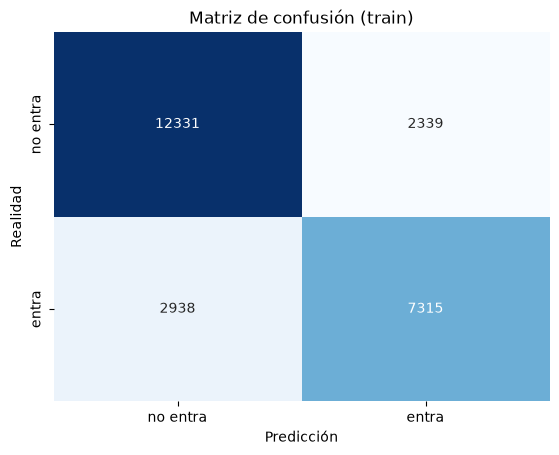

scikit-learn -> accuracy 0.788   precision 0.758   recall 0.713   F1 0.735
AUC: 0.883


In [13]:
pred_train = modelo.predict(X_train_esc)     
prob_train = modelo.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

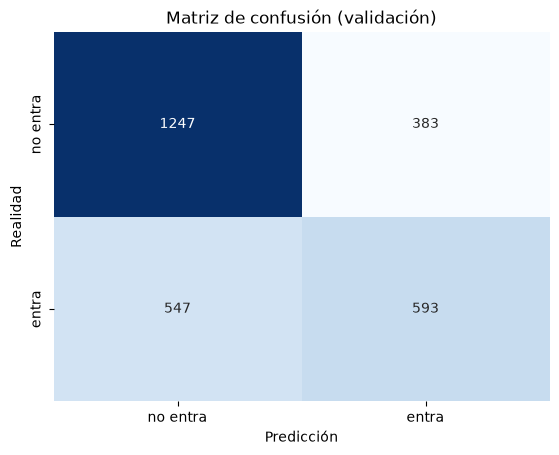

scikit-learn -> accuracy 0.664   precision 0.608   recall 0.520   F1 0.560
AUC: 0.674


In [14]:
pred_val = modelo.predict(X_val_esc)     
prob_val = modelo.predict_proba(X_val_esc)[:, 1]  

cm = confusion_matrix(y_val, pred_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (validación)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_val, pred_val):.3f}   '
      f'precision {precision_score(y_val, pred_val):.3f}   '
      f'recall {recall_score(y_val, pred_val):.3f}   F1 {f1_score(y_val, pred_val):.3f}')

print('AUC:', round(roc_auc_score(y_val, prob_val), 3))

## Tomando decidiones:
- Viendo los resultados nos dimos cuenta de que el modelo tenía sobreajuste. Investigando descubrimos que se debía a la cantidad de cantantes que se generaban iguales después del OneHotEncoder y el modelo daba mucha importancia y basaba toda su predicción en esta columna de tal forma que memorizaba las canciones.

Las soluciones que tomamos fueron:

- Reduccir el número de cantantes sustituyendo los de poca relevancia por la categoria 'Otros'.
- Al perder mucho dinero en los falsos positivos prevalecer que diga que una canción no entra aunque luego se equivoque.
- Modificar C (hiperparámetro de LogisticRegression -> A más pequeño es C más penaliza al modelo por ser complejo).

In [31]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]

encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist", 
    min_frequency=30,
    drop="first",
    sparse_output=False
)
encoder.fit(X_train[texto])
nombres = encoder.get_feature_names_out(texto)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val   = pd.DataFrame(encoder.transform(X_val[texto]),   columns=nombres, index=X_val.index)
cat_test  = pd.DataFrame(encoder.transform(X_test[texto]),  columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val   = pd.concat([X_val.drop(columns=texto),   cat_val],   axis=1)
X_test  = pd.concat([X_test.drop(columns=texto),  cat_test],  axis=1)

print("Columnas del modelo:", X_train.shape[1]) 
print("Nulos -> Train:", X_train.isna().sum().sum(),
      "| Val:", X_val.isna().sum().sum(),
      "| Test:", X_test.isna().sum().sum())   


Columnas del modelo: 230
Nulos -> Train: 0 | Val: 0 | Test: 0


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [32]:

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc   = scaler.transform(X_val)
X_test_esc  = scaler.transform(X_test)

print(f"{'C':<8}{'AUC train':<12}{'AUC val':<12}{'Diferencia'}")
for C in [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]:
    m = LogisticRegression(C=C, max_iter=2000)
    m.fit(X_train_esc, y_train)
    auc_tr = roc_auc_score(y_train, m.predict_proba(X_train_esc)[:, 1])
    auc_va = roc_auc_score(y_val,   m.predict_proba(X_val_esc)[:, 1])
    print(f"{C:<8}{auc_tr:<12.3f}{auc_va:<12.3f}{auc_tr - auc_va:.3f}")

C       AUC train   AUC val     Diferencia
0.0005  0.685       0.686       -0.001
0.001   0.687       0.687       0.000
0.005   0.689       0.689       0.000
0.01    0.689       0.689       0.001
0.05    0.690       0.689       0.001
0.1     0.690       0.689       0.001
0.5     0.690       0.689       0.001
1       0.690       0.689       0.001


## Nos quedamos el mejor C

In [33]:
C_elegido = 0.01 

modelo2 = LogisticRegression(C=C_elegido, max_iter=2000)
modelo2.fit(X_train_esc, y_train)

probs_val = modelo2.predict_proba(X_val_esc)[:, 1]

print(f"{'umbral':<9}{'precisión':<11}{'recall':<9}{'canciones aprobadas'}")
for umbral in [0.40, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    pred = (probs_val >= umbral).astype(int)
    print(f"{umbral:<9.2f}{precision_score(y_val, pred, zero_division=0):<11.3f}"
          f"{recall_score(y_val, pred):<9.3f}{pred.sum()}")

umbral   precisión  recall   canciones aprobadas
0.40     0.581      0.525    1029
0.50     0.758      0.295    443
0.55     0.784      0.276    402
0.60     0.809      0.256    361
0.65     0.821      0.241    335
0.70     0.831      0.220    302
0.75     0.847      0.195    262
0.80     0.843      0.160    216


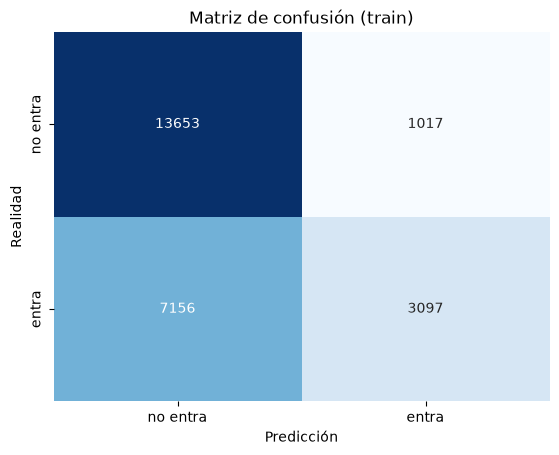

scikit-learn -> accuracy 0.672   precision 0.753   recall 0.302   F1 0.431
AUC: 0.689


In [34]:
pred_train = modelo2.predict(X_train_esc)     
prob_train = modelo2.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

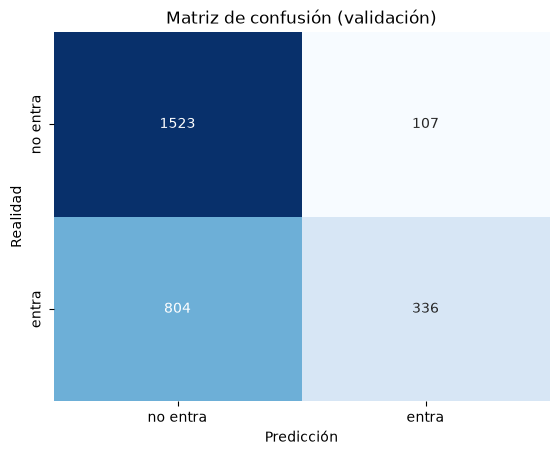

scikit-learn -> accuracy 0.671   precision 0.758   recall 0.295   F1 0.425
AUC: 0.689


In [35]:
pred_val = modelo2.predict(X_val_esc)     
prob_val = modelo2.predict_proba(X_val_esc)[:, 1]  

cm = confusion_matrix(y_val, pred_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (validación)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_val, pred_val):.3f}   '
      f'precision {precision_score(y_val, pred_val):.3f}   '
      f'recall {recall_score(y_val, pred_val):.3f}   F1 {f1_score(y_val, pred_val):.3f}')

print('AUC:', round(roc_auc_score(y_val, prob_val), 3))

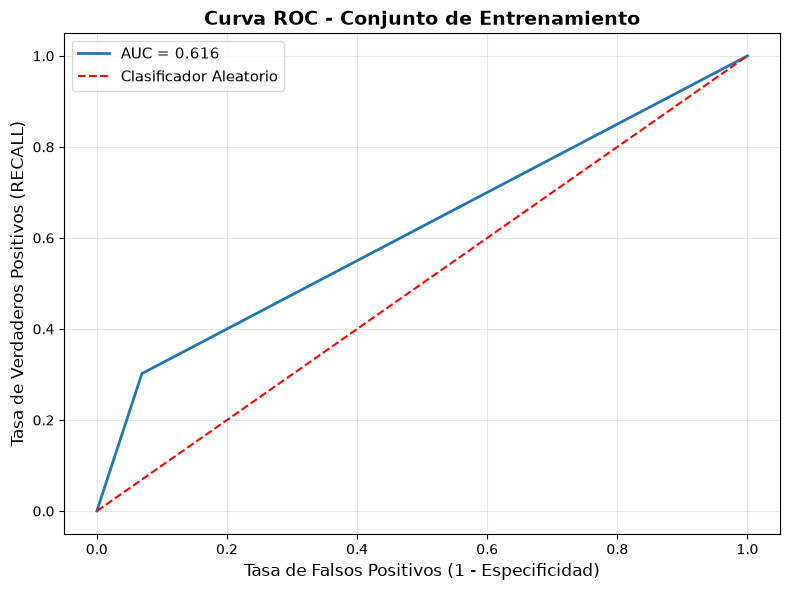

In [36]:
train_auc = roc_auc_score(y_train, pred_train)
fpr_train, tpr_train, _ = roc_curve(y_train, pred_train)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'AUC = {train_auc:.3f}', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Clasificador Aleatorio')
plt.title('Curva ROC - Conjunto de Entrenamiento', fontsize=14, fontweight='bold')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (RECALL)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Probamos el modelo con test

In [37]:
X_test_esc = scaler.transform(X_test)
probs_test = modelo2.predict_proba(X_test_esc)[:, 1]
predicciones_test = (probs_test >= 0.5).astype(int)

print("MÉTRICAS EN TEST")
print("Accuracy:", accuracy_score(y_test, predicciones_test))
print("Precision:", precision_score(y_test, predicciones_test))
print("Recall:", recall_score(y_test, predicciones_test))
print("F1-score:", f1_score(y_test, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_test, probs_test))

MÉTRICAS EN TEST
Accuracy: 0.6640675763482781
Precision: 0.7265625
Recall: 0.2938388625592417
F1-score: 0.4184476940382452
ROC-AUC: 0.6802451795821433


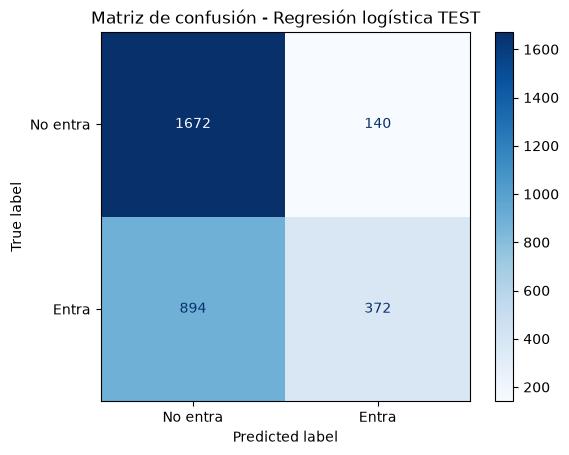

In [38]:
matriz = confusion_matrix(y_test, predicciones_test)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No entra", "Entra"]
).plot(cmap="Blues")

plt.title("Matriz de confusión - Regresión logística TEST")
plt.show()

## Guardar modelo

In [ ]:
joblib.dump(modelo2, "../model/modelo_regresion_lineal.pkl")

['../model/modelo_regresion_lineal.pkl']

## Reflexión final

Tras entrenar y evaluar el modelo de regresión logística, se han obtenido resultados moderados, destacando especialmente su precision de 0.753, aunque presenta un recall relativamente bajo de 0.302 y un F1-score de 0.431.

La precisión es la métrica más destacable de este modelo, ya que indica que aproximadamente el 75,3 % de las canciones clasificadas como potenciales éxitos realmente alcanzan el Top 30 de Billboard 100. Desde el punto de vista empresarial de la IA, este comportamiento resulta interesante, puesto que permite realizar recomendaciones relativamente fiables y reducir el riesgo de invertir recursos promocionales en canciones que finalmente no alcancen el objetivo esperado.

Sin embargo, esta precisión elevada viene acompañada de un recall de 0.302. Esto significa que el modelo solamente consigue identificar aproximadamente el 30,2 % de las canciones que realmente alcanzan el Top 30, dejando sin detectar cerca del 69,8 % de los casos positivos. Por tanto, aunque sus recomendaciones suelen ser acertadas, tiene dificultades para identificar una parte importante de las canciones con potencial comercial.

Por otra parte, el accuracy de 0.672 refleja que el modelo clasifica correctamente aproximadamente el 67,2 % de las canciones analizadas. El ROC-AUC de 0.689 indica una capacidad de discriminación relativamente limitada entre las canciones que alcanzan el Top 30 y aquellas que no. Asimismo, el F1-score de 0.431 muestra que existe un desequilibrio importante entre la precisión y el recall.

En comparación con otros modelos, la regresión logística presenta un comportamiento similar al de la red neuronal en cuanto a precisión y recall. Sin embargo, obtiene un ROC-AUC inferior al de esta última (0.689 frente a 0.743), lo que indica que su capacidad para distinguir entre ambas clases es menor.

En conclusión, considero que la regresión logística puede servir como modelo de referencia para el problema planteado, ya que permite obtener predicciones y estimar la probabilidad de que una canción alcance el Top 30. No obstante, su bajo recall y su capacidad de discriminación relativamente limitada hacen que todavía presente importantes limitaciones para identificar canciones con potencial comercial.

Por tanto, mantendría este modelo como una referencia para comparar los resultados de algoritmos más complejos, pero no lo seleccionaría como modelo definitivo sin estudiar posibles mejoras, como el ajuste del umbral de clasificación o la optimización de sus parámetros.